<a href="https://colab.research.google.com/github/erickvaldezsallagos/SISTEMAS-FINANCIEROS-Y-COMERCIALES/blob/main/ejercicios_parcial2sfyc.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EQUIPO 3:
VALDEZ SALLAGOS ERICK\
CASTILLO DE LA TORRE ARES\
CRUZ PÉREZ REYNA LIZBETH\

PARCIAL 2

Estaremos trabajando con las datos historicos de las siguientes acciones:\
**KO:** BAJA VOLATILIDAD\
**AAPL:** MEDIA VOLATILIDAD\
**TSLA:** ALTA VOLATILIDAD\

Ahora procedemos a bajar la data historica de estas acciones en Yahoo Finanzas

Calcularemos la volatilidad diaria, de los últimos dos años

In [1]:
import numpy as np
import pandas as pd

# 1. Cargar datos del Excel original
archivo = "Accionesescogidas.xlsx"
df_precios = pd.read_excel(archivo, sheet_name="Precios_Cierre")
df_excel = pd.read_excel(archivo, sheet_name="Rendimientos_Diarios")

# 2. Calcular rendimientos logarítmicos exactos
df_rend = pd.DataFrame()
df_rend["Fecha"] = pd.to_datetime(df_precios["Date"])
tickers = ["AAPL", "KO", "TSLA"]

for t in tickers:
  df_rend[t] = np.log(df_precios[t] / df_precios[t].shift(1))

# 3. Parámetros idénticos (Ventana = 252, Lambda = 0.94, Inicio = índice 755)
ventana = 252
lam = 0.94
start_idx = 755

for t in tickers:
  # Volatilidad Paramétrica
  vol_param = df_rend[t].rolling(window=ventana).std(ddof=1)
  vol_param.iloc[:start_idx] = np.nan
  df_rend[f"Vol Paramétrica {t}"] = vol_param

  # Volatilidad EWMA
  ewma = [np.nan] * len(df_rend)
  ewma[start_idx] = vol_param.iloc[start_idx]
  for i in range(start_idx + 1, len(df_rend)):
    ewma[i] = np.sqrt(
        lam * (ewma[i - 1] ** 2) + (1 - lam) * (df_rend[t].iloc[i - 1] ** 2)
    )
  df_rend[f"Vol EWMA {t}"] = ewma

  # Media Móvil 252d
  media_252 = df_rend[t].rolling(window=ventana).mean()
  media_252.iloc[:start_idx] = np.nan
  df_rend[f"Media 252 dias {t}"] = media_252

# 4. IMPRIMIR LOS RESULTADOS DIRECTAMENTE EN PANTALLA (CONSOLA)
print("RESULTADOS FINALES EN PYTHON (Corte: 8 de diciembre de 2023)")

for t in tickers:
  # Tomamos la última fila válida (correspondiente al 8 de diciembre de 2023)
  idx_final = len(df_rend) - 1

  print(f"\n--- ACCIÓN: {t} ---")
  print(f"Fecha: {df_rend['Fecha'].iloc[idx_final].strftime('%Y-%m-%d')}")
  print(
      f"  > Volatilidad Paramétrica: {df_rend[f'Vol Paramétrica {t}'].iloc[idx_final]:.8f}"
  )
  print(
      f"  > Volatilidad EWMA (λ=0.94): {df_rend[f'Vol EWMA {t}'].iloc[idx_final]:.8f}"
  )
  print(
      f"  > Media Móvil 252d:          {df_rend[f'Media 252 dias {t}'].iloc[idx_final]:.8f}"
  )

print("¡Ejecución finalizada en consola con éxito (sin generar archivos)!")

RESULTADOS FINALES EN PYTHON (Corte: 8 de diciembre de 2023)

--- ACCIÓN: AAPL ---
Fecha: 2023-12-08
  > Volatilidad Paramétrica: 0.01362755
  > Volatilidad EWMA (λ=0.94): 0.01038099
  > Media Móvil 252d:          0.00132490

--- ACCIÓN: KO ---
Fecha: 2023-12-08
  > Volatilidad Paramétrica: 0.00848358
  > Volatilidad EWMA (λ=0.94): 0.00721569
  > Media Móvil 252d:          -0.00019723

--- ACCIÓN: TSLA ---
Fecha: 2023-12-08
  > Volatilidad Paramétrica: 0.03623505
  > Volatilidad EWMA (λ=0.94): 0.02604963
  > Media Móvil 252d:          0.00133820
¡Ejecución finalizada en consola con éxito (sin generar archivos)!


**Gráficas de las volatilidades**

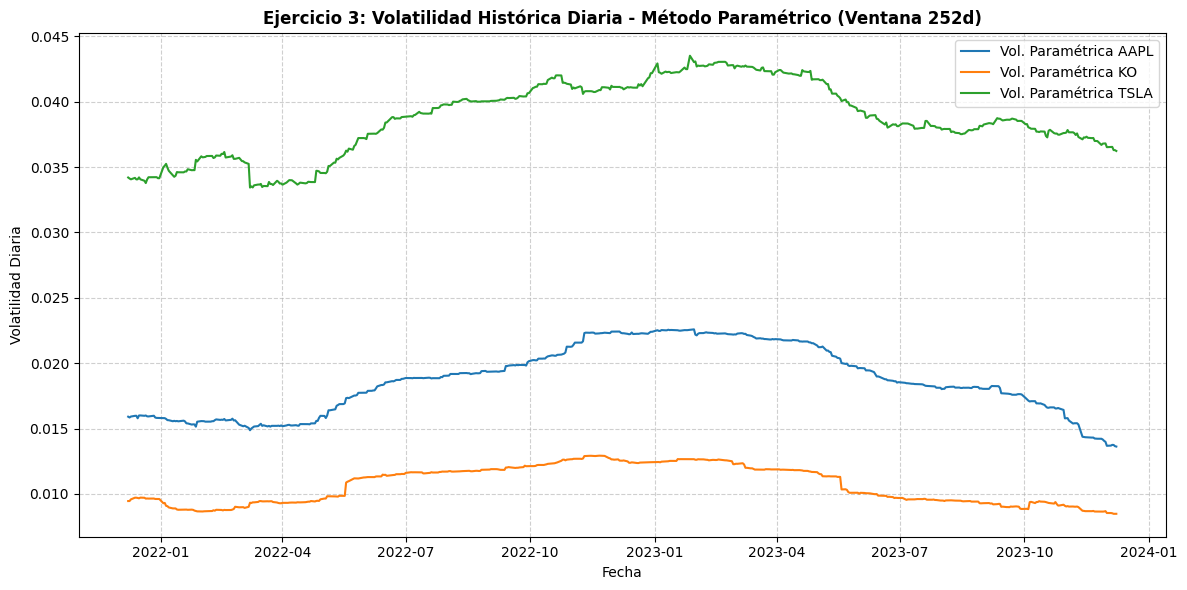

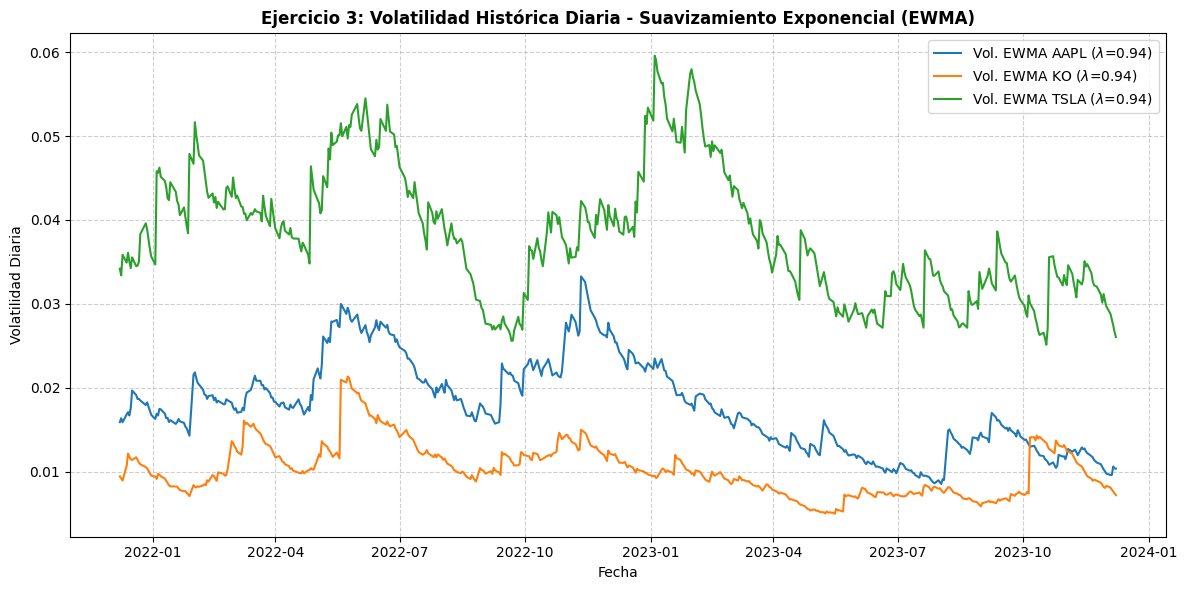

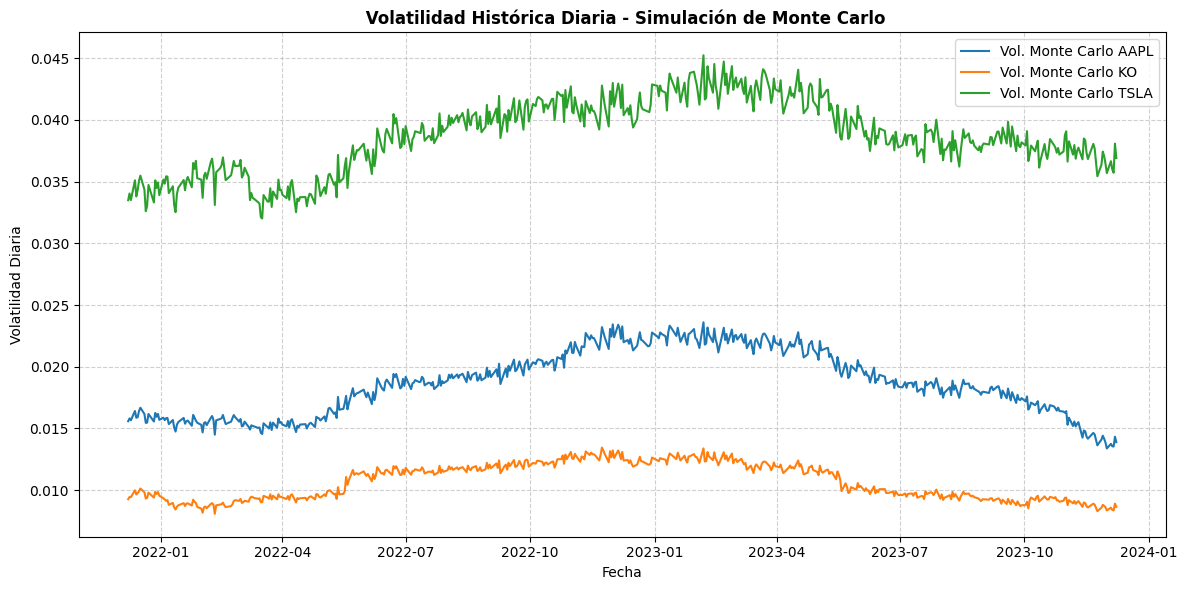

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

archivo = "Accionesescogidas.xlsx"
df_precios = pd.read_excel(archivo, sheet_name="Precios_Cierre")

# Asegurar orden cronológico
df_precios["Date"] = pd.to_datetime(df_precios["Date"])
df_precios = df_precios.sort_values("Date").reset_index(drop=True)

tickers = ["AAPL", "KO", "TSLA"]

# 2. Calcular los rendimientos logarítmicos exactos: ln(P_t / P_{t-1})
df_rend = pd.DataFrame()
df_rend["Fecha"] = df_precios["Date"]

for t in tickers:
  df_rend[t] = np.log(df_precios[t] / df_precios[t].shift(1))

# 3. Parámetros idénticos al Excel
ventana = 252  # Ventana móvil de 1 año bursátil (252 días)
lam = 0.94  # Factor Lambda para EWMA
start_idx = 755  # Fila de inicio exacta para los últimos dos años (08-dic-2021)

for t in tickers:
  # A. Volatilidad Paramétrica (Desviación estándar muestral ddof=1)
  vol_param = df_rend[t].rolling(window=ventana).std(ddof=1)
  vol_param.iloc[:start_idx] = np.nan
  df_rend[f"Vol Paramétrica {t}"] = vol_param

  # B. Volatilidad EWMA (Suavizamiento Exponencial con lambda = 0.94)
  ewma = [np.nan] * len(df_rend)
  ewma[start_idx] = vol_param.iloc[start_idx]
  for i in range(start_idx + 1, len(df_rend)):
    ewma[i] = np.sqrt(
        lam * (ewma[i - 1] ** 2) + (1 - lam) * (df_rend[t].iloc[i - 1] ** 2)
    )
  df_rend[f"Vol EWMA {t}"] = ewma

  # C. Volatilidad por Simulación de Monte Carlo (1,000 simulaciones estocásticas por día)
  np.random.seed(42)
  mc = [np.nan] * len(df_rend)
  for i in range(start_idx, len(df_rend)):
    ventana_datos = df_rend[t].iloc[i - ventana + 1 : i + 1]
    sim = np.random.normal(
        ventana_datos.mean(), ventana_datos.std(ddof=1), size=1000
    )
    mc[i] = np.std(sim, ddof=1)
  df_rend[f"Vol Montecarlo {t}"] = mc

# ==========================================
# 4. GENERACIÓN DE GRÁFICAS COMPARATIVAS
# ==========================================

# Filtrar el periodo de análisis (últimos dos años)
df_plot = df_rend.iloc[start_idx:].copy()

# Gráfica 1: Volatilidad Paramétrica
plt.figure(figsize=(12, 6))
for t in tickers:
  plt.plot(
      df_plot["Fecha"],
      df_plot[f"Vol Paramétrica {t}"],
      label=f"Vol. Paramétrica {t}",
      linewidth=1.5,
  )
plt.title(
    "Ejercicio 3: Volatilidad Histórica Diaria - Método Paramétrico (Ventana 252d)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Fecha")
plt.ylabel("Volatilidad Diaria")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# Gráfica 2: Volatilidad Suavizamiento Exponencial (EWMA)
plt.figure(figsize=(12, 6))
for t in tickers:
  plt.plot(
      df_plot["Fecha"],
      df_plot[f"Vol EWMA {t}"],
      label=f"Vol. EWMA {t} ($\\lambda$=0.94)",
      linewidth=1.5,
  )
plt.title(
    "Ejercicio 3: Volatilidad Histórica Diaria - Suavizamiento Exponencial (EWMA)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Fecha")
plt.ylabel("Volatilidad Diaria")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# Gráfica 3: Volatilidad por Simulación de Monte Carlo
plt.figure(figsize=(12, 6))
for t in tickers:
  plt.plot(
      df_plot["Fecha"],
      df_plot[f"Vol Montecarlo {t}"],
      label=f"Vol. Monte Carlo {t}",
      linewidth=1.5,
  )
plt.title(
    " Volatilidad Histórica Diaria - Simulación de Monte Carlo",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Fecha")
plt.ylabel("Volatilidad Diaria")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


In [6]:
import numpy as np
import pandas as pd


archivo = "Accionesescogidas.xlsx"
df_precios = pd.read_excel(archivo, sheet_name="Precios_Cierre")
df_rend = pd.read_excel(archivo, sheet_name="Rendimientos_Diarios")

# Asegurar orden cronológico
df_precios["Date"] = pd.to_datetime(df_precios["Date"])
df_precios = df_precios.sort_values("Date").reset_index(drop=True)

tickers = ["KO", "AAPL", "TSLA"]

# Ventana de los últimos 504 días (filas 757 a 1260 en Excel -> índices 756 a 1259)
ventana_504 = df_rend.iloc[756:1260].copy()

# Pesos asignados al portafolio (Moderado-Conservador)
pesos = {"KO": 0.50, "AAPL": 0.35, "TSLA": 0.15}

# Volatilidades diarias promedio (Paramétrica y EWMA)
vol_param = {
    "KO": ventana_504["Vol Paramétrica KO"].mean(),
    "AAPL": ventana_504["Vol Paramétrica AAPL"].mean(),
    "TSLA": ventana_504["Vol Paramétrica TSLA"].mean(),
}

vol_ewma = {
    "KO": ventana_504["Vol EWMA KO"].mean(),
    "AAPL": ventana_504["Vol EWMA AAPL"].mean(),
    "TSLA": ventana_504["Vol EWMA TSLA"].mean(),
}

# Volatilidad anualizada individual (252 días)
vol_anual = {t: vol_param[t] * np.sqrt(252) for t in tickers}

# Volatilidad sin diversificar (Promedio ponderado)
vol_diaria_sin_div = sum(pesos[t] * vol_param[t] for t in tickers)

# Matriz de Correlación de los rendimientos en la ventana
rets_504 = ventana_504[["KO", "AAPL", "TSLA"]]
matriz_corr = rets_504.corr()

# Volatilidad real del portafolio (considerando correlaciones y covarianzas)
w = np.array([pesos["KO"], pesos["AAPL"], pesos["TSLA"]])
cov_matrix = rets_504.cov() * 252  # Anualizada o en varianza diaria
# Varianza diaria real del portafolio: w^T * Cov * w
cov_diaria = rets_504.cov()
var_port_diaria = np.dot(w.T, np.dot(cov_diaria, w))
vol_port_diaria_real = np.sqrt(var_port_diaria)
vol_port_anual_real = vol_port_diaria_real * np.sqrt(252)

print("=" * 75)
print(
    " CONSTRUCCIÓN Y DIVERSIFICACIÓN DEL PORTAFOLIO "
)
print(f"• Perfil Seleccionado: Moderado-Conservador")
print(f"• Pesos Asignados: KO={pesos['KO']:.0%}, AAPL={pesos['AAPL']:.0%}, TSLA={pesos['TSLA']:.0%}")
print(
    f"• Volatilidad Diaria Sin Diversificar: {vol_diaria_sin_div * 100:.4f}%"
)
print(
    f"• Volatilidad Diaria Real del Portafolio: {vol_port_diaria_real * 100:.4f}%"
)
print(
    f"• Volatilidad Anualizada Real del Portafolio:"
    f" {vol_port_anual_real * 100:.2f}%"
)
reduccion_riesgo = (vol_diaria_sin_div - vol_port_diaria_real) / vol_diaria_sin_div
print(f"• Reducción de Riesgo por Diversificación: {reduccion_riesgo * 100:.2f}%")

print("\n--- Matriz de Correlación (Ventana 504 días) ---")
print(matriz_corr.round(4))

 CONSTRUCCIÓN Y DIVERSIFICACIÓN DEL PORTAFOLIO 
• Perfil Seleccionado: Moderado-Conservador
• Pesos Asignados: KO=50%, AAPL=35%, TSLA=15%
• Volatilidad Diaria Sin Diversificar: 1.7690%
• Volatilidad Diaria Real del Portafolio: 1.3702%
• Volatilidad Anualizada Real del Portafolio: 21.75%
• Reducción de Riesgo por Diversificación: 22.54%

--- Matriz de Correlación (Ventana 504 días) ---
          KO    AAPL    TSLA
KO    1.0000  0.4234  0.1576
AAPL  0.4234  1.0000  0.5849
TSLA  0.1576  0.5849  1.0000


In [7]:
capital_total = 1000000.00
tipo_cambio = 17.35

# Precios de cierre al 08 de diciembre de 2023 (última fila de Precios_Cierre)
precios_cierre_usd = {
    "KO": df_precios["KO"].iloc[-1],
    "AAPL": df_precios["AAPL"].iloc[-1],
    "TSLA": df_precios["TSLA"].iloc[-1],
}

print("\n" + "=" * 75)
print(" DISTRIBUCIÓN DE $1,000,000.00 MXN EN EL PORTAFOLIO")
print("=" * 75)
print(f"{'Ticker':<8} | {'Peso':<6} | {'Monto MXN':<12} | {'Precio USD':<12} | {'Precio MXN':<12} | {'Acc. Enteras':<12} | {'Invertido Real':<14}")
print("-" * 85)

monto_invertido_total = 0
for t in tickers:
  monto_asgn = capital_total * pesos[t]
  p_usd = precios_cierre_usd[t]
  p_mxn = p_usd * tipo_cambio
  acciones_exactas = monto_asgn / p_mxn
  acciones_enteras = int(np.floor(acciones_exactas))
  invertido_real = acciones_enteras * p_mxn
  monto_invertido_total += invertido_real

  print(
      f"{t:<8} | {pesos[t]:<6.0%} | ${monto_asgn:<11,.2f} |"
      f" ${p_usd:<11.2f} | ${p_mxn:<11.2f} | {acciones_enteras:<12,}"
      f" | ${invertido_real:<13,.2f}"
  )

efectivo_remanente = capital_total - monto_invertido_total
print("-" * 85)
print(f"• Monto Total Invertido en Acciones: ${monto_invertido_total:,.2f} MXN")
print(f"• Efectivo Remanente en Caja:        ${efectivo_remanente:,.2f} MXN")
print("=" * 75)


 EJERCICIO 5: DISTRIBUCIÓN DE $1,000,000.00 MXN EN EL PORTAFOLIO
Ticker   | Peso   | Monto MXN    | Precio USD   | Precio MXN   | Acc. Enteras | Invertido Real
-------------------------------------------------------------------------------------
KO       | 50%    | $500,000.00  | $54.19       | $940.21      | 531          | $499,249.60   
AAPL     | 35%    | $350,000.00  | $193.21      | $3352.12     | 104          | $348,620.76   
TSLA     | 15%    | $150,000.00  | $243.84      | $4230.62     | 35           | $148,071.84   
-------------------------------------------------------------------------------------
• Monto Total Invertido en Acciones: $995,942.20 MXN
• Efectivo Remanente en Caja:        $4,057.80 MXN
